# 13 In-Class Assignment: Projections

<img alt="Graph showing how one vector can be projected onto another vector by forming a right triangle" src="https://upload.wikimedia.org/wikipedia/commons/9/98/Projection_and_rejection.png" width="50%">

Image from: https://en.wikipedia.org/wiki/Vector_projection



---
<a name="Quiz_4_Review"></a>
## 1. Pre-class Review

* [13--Projections_pre-class-assignment](13--Projections_pre-class-assignment.ipynb)

### Note 1:
Please remember to put correct arguments when calling function. In particular, during a function call, values passed through arguments should be in the order of parameters in the function definition. 

### Note 2:
You can copy an existing variable to create a new variable. This may be useful, for example, if you want to create a variable that uses most (if not all) of the same properties of an existing variable, but you want the variable to have a different name.

----
<a name="Understanding_Projections_with_Code"></a>
## 2. Understanding Projections With Code

In this in-class assignment, we are going to avoid some of the more advanced libraries ((i.e. no ```numpy``` or ```scipy``` or ```sympy```) to try to get a better understanding about what is going on in the math. 
The following code implements some common linear algebra functions:

In [1]:
#Standard Python Libraries only
import math
import copy

In [2]:
def dot(u,v):
    '''Calculate the dot product between vectors u and v'''
    if len(u) != len(v):
        print("ERROR -  dimensions not equal")
    else:
        temp = 0;
        for i in range(len(u)):
            temp += u[i]*v[i]
        return temp

In [3]:
def multiply(m1,m2):
    '''Calculate the matrix multiplication between m1 and m2 represented as list-of-list.'''
    n = len(m1)
    d = len(m2)
    m = len(m2[0])
    
    if len(m1[0]) != d:
        print("ERROR - inner dimentions not equal")
    else:
        result = [[0 for i in range(n)] for j in range(m)]
        for i in range(0,n):
            for j in range(0,m):
                for k in range(0,d):
                    result[i][j] = result[i][j] + m1[i][k] * m2[k][j]
        return result

In [4]:
def add_vectors(v1,v2):
    v3 = []
    for i in range(len(v1)):
        v3.append(v1[i]+v2[i])
    return v3

In [5]:
def sub_vectors(v1,v2):
    v3 = []
    for i in range(len(v1)):
        v3.append(v1[i]-v2[i])
    return v3

In [6]:
def norm(u):
    '''Calculate the norm of vector u'''
    nm = 0
    for i in range(len(u)):
        nm += u[i]*u[i]
    return math.sqrt(nm)

In [7]:
def transpose(A):
    '''Calculate the transpose of matrix A represented as list of lists'''
    n = len(A)
    m = len(A[0])
    AT = list()
    for j in range(0,m):    
        temp = list()
        for i in range(0,n):
            temp.append(A[i][j])
        AT.append(temp)
    return AT

### Projection function

&#9989; **<font color=red>DO THIS:</font>** Write a function that projects vector $v$ onto vector $u$. 
Do not use the numpy library. 
Instead use the functions provided above:

$$\mbox{proj}_u v = \frac{v \cdot u}{u \cdot u} u$$

Make sure this function will work for any size of $v$ and $u$. 

In [17]:
def proj(v,u):
    ## Put your code here
    vu = dot(v,u)
    uu = dot(u,u)
    div = vu/uu
    pv = []
    for i in range(len(u)):
        a = div * u[i]
        pv.append(a)
    return pv

Let's test your function. Below are two example vectors. Find the projection of v onto u. Note that the order of variables in your function `proj(.,.)` matters! Make sure you get the correct answers. 
You may want to test this code with more than one set of vectors. 

In [18]:
u = [1,2,0,3]
v = [4,0,5,8]
print(proj(v,u))

[2.0, 4.0, 0.0, 6.0]


In [19]:
from answercheck import checkanswer

checkanswer.vector(proj(v,u),'b400dee73da5b8fa07602efd89f20ac1');


    Trying to convert to a array matrix using ```A = np.matrix(A)```.


    Converting to positive values of zero using  ```A[A==-0] = 0```.

Testing [[2. 4. 0. 6.]]
Answer seems to be correct



### Visualizing projections

&#9989; **<font color=red>DO THIS:</font>** See if you can design and implement a small function that takes two vectors ($a$ and $b$) as inputs and generates a figure similar to the one below.

<img alt="Graph showing how one vector can be projected onto another vector by forming a right triangle" src="https://upload.wikimedia.org/wikipedia/commons/9/98/Projection_and_rejection.png" width="25%">

I.e. a black line from the origin to "$b$", a black line from origin to "$a$"; a green line showing the "$a$" component in the "$b$" direction and a red line showing the "$a$" component orthogonal to the green line. 

Remember that calling `plt.arrow(x,y,dx,dy)` draws an arrow from `(x,y)` to `(x+dx,y+dy)`.

Don't worry about labeling the vectors. Just make sure the green and red vectors are drawn correctly.

In [23]:
import numpy as np

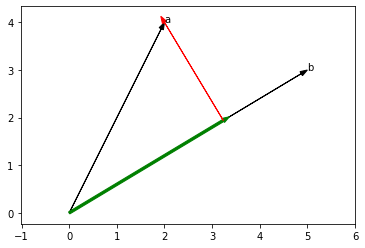

In [38]:
%matplotlib inline
import matplotlib.pylab as plt

b = [5,3]
a = [2,4]

def show_projection(a,b):
    plt.arrow(0,0,a[0],a[1],color='black',head_width=0.1,length_includes_head=True)
    plt.arrow(0,0,b[0],b[1],color='black',head_width=0.1,length_includes_head=True)
    plt.annotate('a',a)
    plt.annotate('b',b)
    
# Compute the projection of a onto b, and the component of a that is perpendicular to b. 
    projab = np.array(proj(a,b))
    plt.arrow(0,0, projab[0], projab[1], head_width = 0.1, width = 0.05,color="green")
    plt.arrow(projab[0],projab[1], a[0]-projab[0], a[1]-projab[1],head_width = 0.1, color="red")

# Then draw arrows representing those vectors
    plt.axis('equal')
    
x = show_projection(a,b) ;

----

<a name="Gram-Schmidt_Orthoganalization_Process"></a>

## 3. Gram-Schmidt Orthoganalization Process

&#9989; **<font color=red>DO THIS:</font>** Implement the Gram-Schmidt orthoganalization process from the [Hefron](http://joshua.smcvt.edu/linearalgebra/book.pdf) textbook (page 282). 
This function takes a $m \times n$ Matrix $A$ with linearly independent columns as input and return a $m \times n$ Matrix $G$ with orthogonal column vectors. 
The basic algorithm works as follows:

- ```AT = transpose(A)``` (this process works with the columns of the matrix so it is easier to work with the transpose. Think about a list of list, it is easy to get a row (a list)).  
- Make a new empty list of the same size as ```AT``` and call it ```GT``` (G transpose)
- Loop index ```i``` over all of the rows in AT (i.e. columns of A) 

    - ```GT[i] = AT[i]```
    - Loop index ```j``` from 0 to ```i```
        - ```GT[i] -= proj(GT[i], GT[j])```
        
        
- ```G = transpose(GT)```

Use the following function definition as a template:

In [88]:
def GramSchmidt(A):
    AT = transpose(A)
    GT = np.zeros_like(AT)
    for i in range(len(AT)):
        GT[i] = AT[i]
        for j in range(0,i):
#             print(GT)
            GT[i] = sub_vectors(GT[i], proj(GT[i], GT[j]))
    G = transpose(GT)
    return G

Here, we are going to test your function using the vectors:

In [89]:
A4 = [[1,4,8],[2,0,1],[0,5,5],[3,8,6]]
print(transpose(A4))
G4 = GramSchmidt(A4)
print(transpose(G4))

[[1, 2, 0, 3], [4, 0, 5, 8], [8, 1, 5, 6]]
[[1, 2, 0, 3], [2, -4, 5, 2], [4, 1, 0, -2]]


In [90]:
from answercheck import checkanswer

checkanswer.matrix(G4,'a472a81eef411c0df03ae9a072dfa040');


    Trying to convert to a array matrix using ```A = np.matrix(A)```.


    Trying to convert to float using ```A = A.astype(float)```.


    Converting to positive values of zero using  ```A[A==-0] = 0```.

Testing [[ 1.  2.  4.]
 [ 2. -4.  1.]
 [ 0.  5.  0.]
 [ 3.  2. -2.]]
Answer seems to be correct



In [91]:
A2 = [[-4,-6],[3,5]]
print(transpose(A2))
G2 = GramSchmidt(A2)
print(transpose(G2))

[[-4, 3], [-6, 5]]
[[-4, 3], [0, 0]]


In [92]:
from answercheck import checkanswer

checkanswer.matrix(G2,'23b9860b72dbe5b84d7c598c08af9688');


    Trying to convert to a array matrix using ```A = np.matrix(A)```.


    Trying to convert to float using ```A = A.astype(float)```.


    Converting to positive values of zero using  ```A[A==-0] = 0```.

Testing [[-4.  0.]
 [ 3.  0.]]
Answer seems to be incorrect



AssertionError: Answer is incorrect 188c0d9826dcb77519708444232f9092

&#9989; **<font color=red>QUESTION:</font>** What is the Big-O complexity of the Gram-Schmidt process? 

O(n^2)

----

Written by Dr. Dirk Colbry, Michigan State University
<a rel="license" href="http://creativecommons.org/licenses/by-nc/4.0/"><img alt="Creative Commons License" style="border-width:0" src="https://i.creativecommons.org/l/by-nc/4.0/88x31.png" /></a><br />This work is licensed under a <a rel="license" href="http://creativecommons.org/licenses/by-nc/4.0/">Creative Commons Attribution-NonCommercial 4.0 International License</a>.

###STARTFOOTER###

-----
### Congratulations, we're done!

----